# 01 · Análisis exploratorio (EDA) de la tienda

Objetivo: conocer los datos limpios de `data/processed/tienda.db` antes de entrenar modelos.
Todas las consultas se hacen en **SQL** (con `leer_sql` de `src/bd.py`); pandas solo se usa para
cálculos pequeños sobre el resultado y para los gráficos.

> Requisito: haber ejecutado `python src/generar_datos.py` y `python src/limpieza.py`.

**Criterio de ingresos:** solo cuentan los pedidos con estado `completado`
(un pedido cancelado o devuelto no es dinero que se quede la tienda).

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns

# El notebook se ejecuta desde la carpeta notebooks/, así que src/ está en ../src
RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ / "src"))
from bd import leer_sql, ventas_por_linea  # noqa: E402  (se importa después de tocar el path)

# Carpeta donde se guardan los gráficos principales
CARPETA_IMG = RAIZ / "docs" / "img"
CARPETA_IMG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)

# Colores: un único azul para las series de ventas y naranja para la publicidad
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"


def euros(valor, decimales=0):
    """12345.6 -> '12.346 €' (formato español: punto para miles, coma para decimales)."""
    texto = f"{valor:,.{decimales}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{texto} €"


def porcentaje(valor, decimales=1):
    """0.1234 -> '12,3 %'."""
    return f"{valor * 100:.{decimales}f} %".replace(".", ",")


# Formateador para poner euros en los ejes de matplotlib
FORMATO_EUROS = mticker.FuncFormatter(lambda valor, _pos: euros(valor))


def guardar(fig, nombre):
    """Guarda la figura en docs/img/eda_<nombre>.png."""
    # metadata={"Software": None}: sin la versión de matplotlib en el PNG, para que el archivo
    # sea idéntico byte a byte entre ejecuciones (y git no lo marque como cambiado)
    fig.savefig(CARPETA_IMG / f"eda_{nombre}.png", dpi=120, bbox_inches="tight",
                metadata={"Software": None})

## 1. Vista general

In [2]:
# Filas de cada tabla: una consulta COUNT(*) por tabla, unidas con UNION ALL
filas = leer_sql("""
    SELECT 'categorias'     AS tabla, COUNT(*) AS filas FROM categorias
    UNION ALL
    SELECT 'proveedores',             COUNT(*)          FROM proveedores
    UNION ALL
    SELECT 'productos',               COUNT(*)          FROM productos
    UNION ALL
    SELECT 'clientes',                COUNT(*)          FROM clientes
    UNION ALL
    SELECT 'pedidos',                 COUNT(*)          FROM pedidos
    UNION ALL
    SELECT 'detalle_pedido',          COUNT(*)          FROM detalle_pedido
    UNION ALL
    SELECT 'campanas',                COUNT(*)          FROM campanas
""")
filas

,tabla,filas
0,categorias,6
1,proveedores,8
2,productos,60
3,clientes,493
4,pedidos,7297
5,detalle_pedido,11879
6,campanas,72


In [3]:
# Periodo cubierto por los pedidos y por las campañas
periodo = leer_sql("""
    SELECT
        (SELECT MIN(fecha_pedido) FROM pedidos)                          AS primer_pedido,
        (SELECT MAX(fecha_pedido) FROM pedidos)                          AS ultimo_pedido,
        (SELECT COUNT(DISTINCT strftime('%Y-%m', fecha_pedido)) FROM pedidos) AS meses_con_pedidos,
        (SELECT MIN(mes) FROM campanas)                                  AS primera_campana,
        (SELECT MAX(mes) FROM campanas)                                  AS ultima_campana
""")
periodo

,primer_pedido,ultimo_pedido,meses_con_pedidos,primera_campana,ultima_campana
0,2024-11-04,2026-10-31,24,2024-11,2026-10


In [4]:
# Tabla de ventas por línea (JOIN de 5 tablas, ver src/bd.py) y sus tipos de datos
ventas = ventas_por_linea()
print(f"{len(ventas)} líneas de venta, {ventas['id_pedido'].nunique()} pedidos")
ventas.dtypes

11879 líneas de venta, 7297 pedidos


id_pedido                   int64
fecha_pedido       datetime64[us]
estado                        str
metodo_pago                   str
id_cliente                  int64
ciudad                        str
fecha_alta         datetime64[us]
id_producto                 int64
producto                      str
categoria                     str
precio_catalogo           float64
coste                     float64
cantidad                    int64
precio_unitario           float64
importe                   float64
dtype: object

In [5]:
ventas.head()

,id_pedido,fecha_pedido,estado,metodo_pago,id_cliente,ciudad,fecha_alta,id_producto,producto,categoria,precio_catalogo,coste,cantidad,precio_unitario,importe
0,1,2024-11-04,completado,bizum,468,Valencia,2024-11-04,39,Bufanda Básico,Moda,15.63,9.77,3,15.63,46.89
1,3,2024-11-04,completado,tarjeta,468,Valencia,2024-11-04,30,Mochila deportiva Premium,Deporte,54.65,39.55,3,54.65,163.95
2,3,2024-11-04,completado,tarjeta,468,Valencia,2024-11-04,46,Guía de viajes Premium,Libros,29.15,19.53,2,29.15,58.30
3,4,2024-11-04,completado,tarjeta,210,Madrid,2024-11-04,7,Cargador rápido Básico,Electrónica,66.34,48.88,2,66.34,132.68
4,4,2024-11-04,completado,tarjeta,210,Madrid,2024-11-04,52,Crema hidratante Premium,Belleza,62.85,46.43,1,62.85,62.85


**Lectura:** las fechas llegan de SQLite como texto y `ventas_por_linea()` ya las convierte a
`datetime64`; los identificadores son enteros y los importes, `float`. No hay que hacer más
conversiones para analizar.

## 2. Ventas en el tiempo

In [6]:
# Ingresos y nº de pedidos por mes. Solo pedidos completados.
ventas_mes = leer_sql("""
    SELECT
        strftime('%Y-%m', p.fecha_pedido)       AS mes,
        COUNT(DISTINCT p.id_pedido)             AS pedidos,
        SUM(d.cantidad * d.precio_unitario)     AS ingresos
    FROM pedidos AS p
        JOIN detalle_pedido AS d ON d.id_pedido = p.id_pedido
    WHERE p.estado = 'completado'
    GROUP BY mes
    ORDER BY mes
""")

# Inversión publicitaria total de cada mes (suma de los 3 canales)
inversion_mes = leer_sql("""
    SELECT mes, SUM(inversion) AS inversion
    FROM campanas
    GROUP BY mes
    ORDER BY mes
""")

mensual = ventas_mes.merge(inversion_mes, on="mes")
mensual["fecha"] = pd.to_datetime(mensual["mes"])
mensual["es_nov_dic"] = mensual["fecha"].dt.month.isin([11, 12])
mensual

,mes,pedidos,ingresos,inversion,fecha,es_nov_dic
0,2024-11,411,62425.84,4805.81,2024-11-01,True
1,2024-12,372,50417.97,5149.78,2024-12-01,True
2,2025-01,304,42475.15,4490.81,2025-01-01,False
3,2025-02,201,27021.07,2909.23,2025-02-01,False
4,2025-03,232,27495.94,2857.55,2025-03-01,False
5,2025-04,212,28589.63,2125.18,2025-04-01,False
6,2025-05,318,39239.53,3651.81,2025-05-01,False
7,2025-06,261,31654.56,3192.12,2025-06-01,False
8,2025-07,257,33859.34,3506.27,2025-07-01,False
9,2025-08,284,38823.50,4492.53,2025-08-01,False


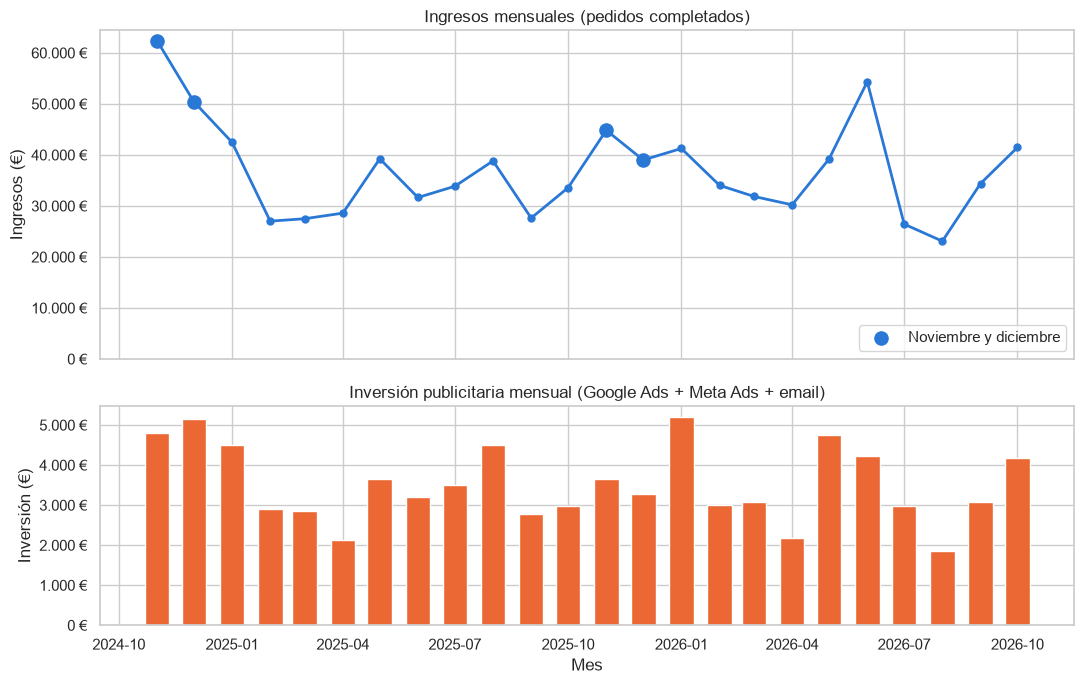

In [7]:
# Dos gráficos alineados (mismo eje X) en lugar de un eje doble:
# con dos escalas en el mismo gráfico es fácil sacar conclusiones falsas
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 2]})

ax1.plot(mensual["fecha"], mensual["ingresos"], color=AZUL, linewidth=2, marker="o", markersize=5)
# Noviembre y diciembre marcados con un punto más grande
pico = mensual[mensual["es_nov_dic"]]
ax1.scatter(pico["fecha"], pico["ingresos"], color=AZUL, s=90, zorder=3, label="Noviembre y diciembre")
ax1.set_title("Ingresos mensuales (pedidos completados)")
ax1.set_ylabel("Ingresos (€)")
ax1.yaxis.set_major_formatter(FORMATO_EUROS)
ax1.set_ylim(bottom=0)
ax1.legend(loc="lower right")

ax2.bar(mensual["fecha"], mensual["inversion"], width=20, color=NARANJA)
ax2.set_title("Inversión publicitaria mensual (Google Ads + Meta Ads + email)")
ax2.set_ylabel("Inversión (€)")
ax2.set_xlabel("Mes")
ax2.yaxis.set_major_formatter(FORMATO_EUROS)

fig.tight_layout()
guardar(fig, "ventas_mensuales")
plt.show()

In [8]:
# Cifras para la conclusión
media_nov_dic = mensual.loc[mensual["es_nov_dic"], "ingresos"].mean()
media_resto = mensual.loc[~mensual["es_nov_dic"], "ingresos"].mean()
mejor = mensual.loc[mensual["ingresos"].idxmax()]
peor = mensual.loc[mensual["ingresos"].idxmin()]

print("Ingresos totales:", euros(mensual["ingresos"].sum()))
print("Media mensual:", euros(mensual["ingresos"].mean()))
print("Media nov-dic:", euros(media_nov_dic), "| media resto de meses:", euros(media_resto))
print("Nov-dic venden un", porcentaje(media_nov_dic / media_resto - 1), "más que la media del resto")
print("Mejor mes:", mejor["mes"], euros(mejor["ingresos"]), "| peor mes:", peor["mes"], euros(peor["ingresos"]))

Ingresos totales: 883.361 €
Media mensual: 36.807 €
Media nov-dic: 49.169 € | media resto de meses: 34.334 €
Nov-dic venden un 43,2 % más que la media del resto
Mejor mes: 2024-11 62.426 € | peor mes: 2026-08 23.093 €


In [9]:
# ¿Hay picos que no se explican por la temporada? Se buscan pedidos excepcionalmente grandes.
# HAVING filtra después de agrupar (WHERE filtra antes)
grandes = leer_sql("""
    SELECT
        p.id_pedido,
        strftime('%Y-%m', p.fecha_pedido)    AS mes,
        COUNT(*)                             AS lineas,
        MAX(d.cantidad)                      AS max_unidades_linea,
        SUM(d.cantidad * d.precio_unitario)  AS importe
    FROM pedidos AS p
        JOIN detalle_pedido AS d ON d.id_pedido = p.id_pedido
    WHERE p.estado = 'completado'
    GROUP BY p.id_pedido
    HAVING importe > 5000
    ORDER BY importe DESC
""")
# Ingresos de esos meses con y sin el pedido grande
grandes = grandes.merge(mensual[["mes", "ingresos"]], on="mes")
grandes["ingresos_sin_pedido"] = grandes["ingresos"] - grandes["importe"]
grandes.round(2)

,id_pedido,mes,lineas,max_unidades_linea,importe,ingresos,ingresos_sin_pedido
0,348,2024-11,1,54,11730.42,62425.84,50695.42
1,6477,2026-06,1,48,10389.60,54351.41,43961.81


**Conclusión:** en 24 meses se ingresan 883.361 € (36.807 € de media al mes). Noviembre y diciembre venden de media 49.169 €, un 43,2 % más que el resto de meses (34.334 €): la estacionalidad se ve claramente. La inversión publicitaria sube y baja de forma parecida a los ingresos (lo medimos en la sección 7). El mejor mes es 2024-11 (62.426 €) y el peor, 2026-08 (23.093 €). Ojo: dos picos se deben en parte a un único pedido enorme (tabla de arriba). Sin ese pedido, 2024-11 bajaría a 50.695 € y 2026-06, a 43.962 €.

## 3. Productos y categorías

In [10]:
# Ingresos por producto (todos los productos, ordenados de más a menos)
productos = leer_sql("""
    SELECT
        pr.nombre                            AS producto,
        ca.nombre                            AS categoria,
        SUM(d.cantidad)                      AS unidades,
        SUM(d.cantidad * d.precio_unitario)  AS ingresos
    FROM detalle_pedido AS d
        JOIN pedidos    AS p  ON p.id_pedido     = d.id_pedido
        JOIN productos  AS pr ON pr.id_producto  = d.id_producto
        JOIN categorias AS ca ON ca.id_categoria = pr.id_categoria
    WHERE p.estado = 'completado'
    GROUP BY pr.id_producto
    ORDER BY ingresos DESC
""")
productos.head(10)

,producto,categoria,unidades,ingresos
0,Auriculares inalámbricos Premium,Electrónica,397,86240.31
1,Smartwatch Premium,Electrónica,326,70562.70
2,Cargador rápido Premium,Electrónica,268,45553.40
3,Smartwatch Básico,Electrónica,266,26086.39
4,Lámpara de escritorio Premium,Hogar,266,25823.28
5,Cafetera Premium,Hogar,287,23358.93
6,Organizador de armario Premium,Hogar,337,23155.27
7,Crema hidratante Premium,Belleza,344,21620.40
8,Kit de maquillaje Premium,Belleza,315,19848.15
9,Champú sólido Premium,Belleza,320,19587.66


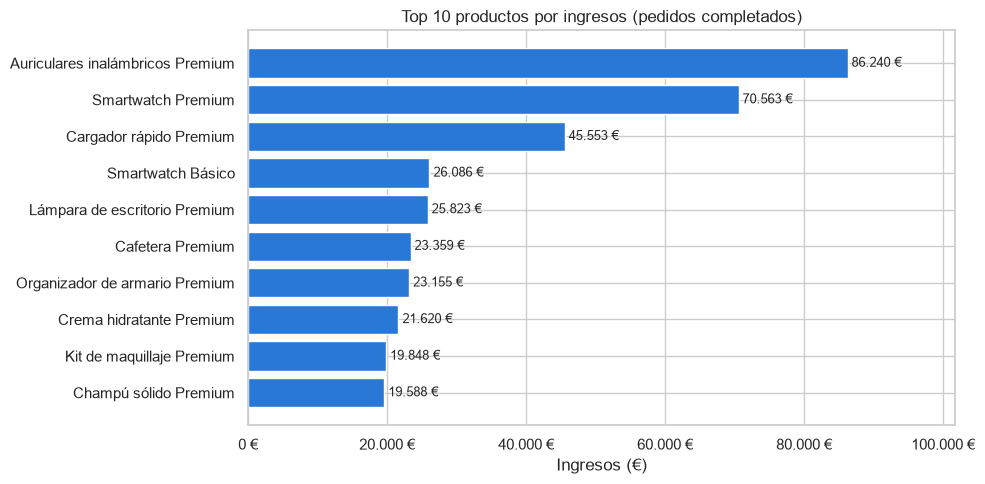

El top 10 suma 41,0 % de los ingresos


In [11]:
# Barras horizontales: los nombres de producto son largos y se leen mejor en el eje Y
top10 = productos.head(10).iloc[::-1]  # al revés para que el primero quede arriba
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top10["producto"], top10["ingresos"], color=AZUL)
ax.set_title("Top 10 productos por ingresos (pedidos completados)")
ax.set_xlabel("Ingresos (€)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(FORMATO_EUROS)
for y, valor in enumerate(top10["ingresos"]):
    ax.text(valor, y, " " + euros(valor), va="center", fontsize=9)
ax.set_xlim(right=top10["ingresos"].max() * 1.18)  # hueco para las etiquetas
fig.tight_layout()
guardar(fig, "top_productos")
plt.show()

print("El top 10 suma", porcentaje(productos.head(10)["ingresos"].sum() / productos["ingresos"].sum()),
      "de los ingresos")

**Conclusión:** los tres productos que más ingresan son de Electrónica y Premium: Auriculares inalámbricos Premium (86.240 €), Smartwatch Premium (70.563 €) y Cargador rápido Premium (45.553 €). Nueve de los diez son Premium: pesa más el precio que el número de unidades. Entre los diez suman el 41,0 % de los ingresos.

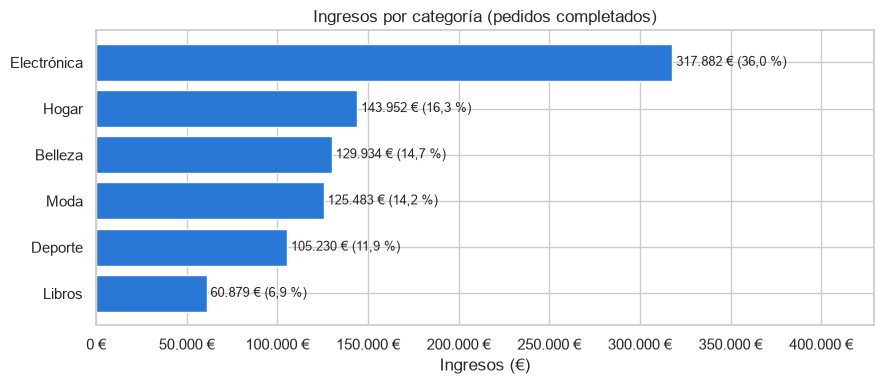

,categoria,pedidos,ingresos,cuota
0,Electrónica,1567,317882.40,"36,0 %"
1,Hogar,1629,143952.32,"16,3 %"
2,Belleza,1640,129934.38,"14,7 %"
3,Moda,1583,125483.09,"14,2 %"
4,Deporte,1593,105229.69,"11,9 %"
5,Libros,1681,60878.66,"6,9 %"


In [12]:
# Ingresos por categoría
categorias = leer_sql("""
    SELECT
        ca.nombre                            AS categoria,
        COUNT(DISTINCT d.id_pedido)          AS pedidos,
        SUM(d.cantidad * d.precio_unitario)  AS ingresos
    FROM detalle_pedido AS d
        JOIN pedidos    AS p  ON p.id_pedido     = d.id_pedido
        JOIN productos  AS pr ON pr.id_producto  = d.id_producto
        JOIN categorias AS ca ON ca.id_categoria = pr.id_categoria
    WHERE p.estado = 'completado'
    GROUP BY ca.id_categoria
    ORDER BY ingresos DESC
""")
categorias["cuota"] = categorias["ingresos"] / categorias["ingresos"].sum()

orden = categorias.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(orden["categoria"], orden["ingresos"], color=AZUL)
ax.set_title("Ingresos por categoría (pedidos completados)")
ax.set_xlabel("Ingresos (€)")
ax.xaxis.set_major_formatter(FORMATO_EUROS)
for y, (valor, cuota) in enumerate(zip(orden["ingresos"], orden["cuota"])):
    ax.text(valor, y, f" {euros(valor)} ({porcentaje(cuota)})", va="center", fontsize=9)
ax.set_xlim(right=orden["ingresos"].max() * 1.35)
fig.tight_layout()
plt.show()
# La cuota se muestra en % para leerla mejor
categorias.assign(cuota=categorias["cuota"].map(porcentaje))

**Conclusión:** Electrónica genera 317.882 € (36,0 % del total), más del doble que la segunda categoría, Hogar (16,3 %). Libros es la última en ingresos (60.879 €, 6,9 %), aunque es la categoría que aparece en más pedidos (1.681): son productos baratos que se venden a menudo.

33 de 60 productos (55,0 %) generan el 80 % de los ingresos


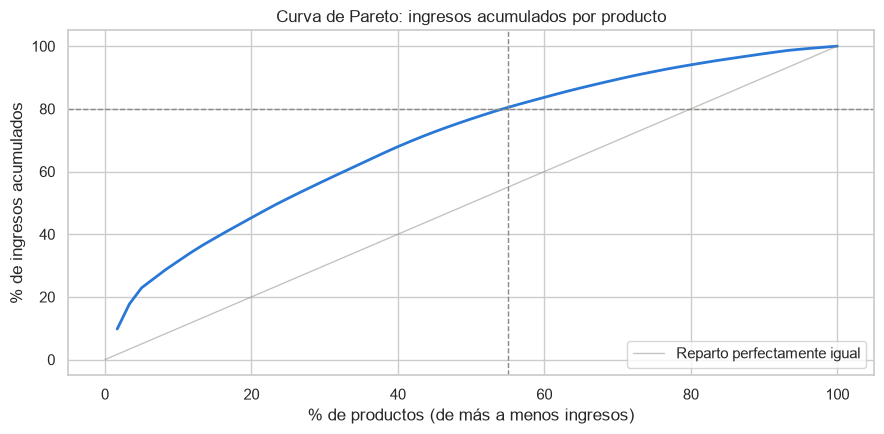

In [13]:
# Pareto: ¿qué porcentaje de productos genera el 80 % de los ingresos?
productos["cuota_acumulada"] = productos["ingresos"].cumsum() / productos["ingresos"].sum()
productos["pct_productos"] = (productos.index + 1) / len(productos)
# Primer producto con el que la cuota acumulada llega al 80 %
n_80 = int((productos["cuota_acumulada"] < 0.80).sum()) + 1
print(f"{n_80} de {len(productos)} productos ({porcentaje(n_80 / len(productos))}) generan el 80 % de los ingresos")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(productos["pct_productos"] * 100, productos["cuota_acumulada"] * 100, color=AZUL, linewidth=2)
ax.axhline(80, color=GRIS, linestyle="--", linewidth=1)
ax.axvline(n_80 / len(productos) * 100, color=GRIS, linestyle="--", linewidth=1)
ax.plot([0, 100], [0, 100], color=GRIS, linewidth=1, alpha=0.5, label="Reparto perfectamente igual")
ax.set_title("Curva de Pareto: ingresos acumulados por producto")
ax.set_xlabel("% de productos (de más a menos ingresos)")
ax.set_ylabel("% de ingresos acumulados")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

**Conclusión:** hacen falta 33 de los 60 productos (55,0 %) para llegar al 80 % de los ingresos. No se cumple la regla 80/20: los ingresos están bastante repartidos, y lo que más concentra es la categoría (Electrónica), no unos pocos productos.

## 4. Pedidos

In [14]:
# Un registro por pedido completado: nº de líneas e importe total
pedidos = leer_sql("""
    SELECT
        p.id_pedido,
        COUNT(*)                             AS lineas,
        SUM(d.cantidad)                      AS unidades,
        SUM(d.cantidad * d.precio_unitario)  AS importe
    FROM pedidos AS p
        JOIN detalle_pedido AS d ON d.id_pedido = p.id_pedido
    WHERE p.estado = 'completado'
    GROUP BY p.id_pedido
""")
pedidos["importe"].describe()

count     6541.000000
mean       135.049769
std        255.368433
min          4.970000
25%         44.080000
50%         82.780000
75%        165.840000
max      11730.420000
Name: importe, dtype: float64

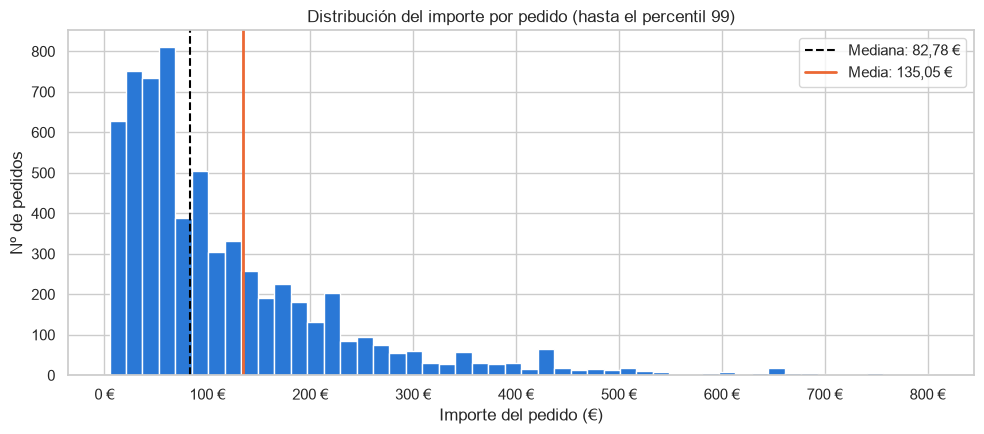

Ticket medio: 135,05 € | ticket mediano: 82,78 €
Percentil 99: 805,29 € | pedido máximo: 11.730,42 €
Pedidos por encima del percentil 99: 66


In [15]:
ticket_medio = pedidos["importe"].mean()
ticket_mediano = pedidos["importe"].median()
p99 = pedidos["importe"].quantile(0.99)

fig, ax = plt.subplots()
# Se corta el eje en el percentil 99 para que la cola larga no aplaste el histograma
ax.hist(pedidos.loc[pedidos["importe"] <= p99, "importe"], bins=50, color=AZUL, edgecolor="white")
ax.axvline(ticket_mediano, color="black", linestyle="--", linewidth=1.5, label=f"Mediana: {euros(ticket_mediano, 2)}")
ax.axvline(ticket_medio, color=NARANJA, linestyle="-", linewidth=2, label=f"Media: {euros(ticket_medio, 2)}")
ax.set_title("Distribución del importe por pedido (hasta el percentil 99)")
ax.set_xlabel("Importe del pedido (€)")
ax.set_ylabel("Nº de pedidos")
ax.xaxis.set_major_formatter(FORMATO_EUROS)
ax.legend()
fig.tight_layout()
plt.show()

print("Ticket medio:", euros(ticket_medio, 2), "| ticket mediano:", euros(ticket_mediano, 2))
print("Percentil 99:", euros(p99, 2), "| pedido máximo:", euros(pedidos["importe"].max(), 2))
print("Pedidos por encima del percentil 99:", int((pedidos["importe"] > p99).sum()))

**Conclusión:** el ticket medio (135,05 €) es mucho mayor que el mediano (82,78 €): la distribución tiene una cola larga hacia la derecha. El 99 % de los pedidos cuesta como mucho 805,29 €, pero el más caro llega a 11.730,42 €. Esos pocos pedidos enormes suben la media, así que para hablar del pedido típico es mejor la mediana.

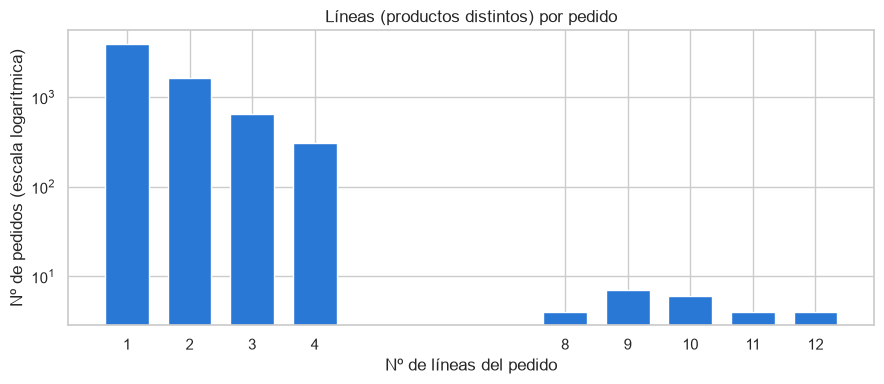

Pedidos con 8 o más líneas: 25


,pedidos,porcentaje
lineas,,
1,3934,"60,1 %"
2,1634,"25,0 %"
3,644,"9,8 %"
4,304,"4,6 %"
8,4,"0,1 %"
9,7,"0,1 %"
10,6,"0,1 %"
11,4,"0,1 %"
12,4,"0,1 %"


In [16]:
# Distribución de líneas por pedido
lineas = pedidos["lineas"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lineas.index, lineas.values, color=AZUL, width=0.7)
ax.set_title("Líneas (productos distintos) por pedido")
ax.set_xlabel("Nº de líneas del pedido")
ax.set_ylabel("Nº de pedidos (escala logarítmica)")
ax.set_yscale("log")  # sin log, los pedidos de 8+ líneas no se verían
ax.set_xticks(lineas.index)
fig.tight_layout()
plt.show()

tabla_lineas = pd.DataFrame({"pedidos": lineas, "porcentaje": (lineas / lineas.sum()).map(porcentaje)})
print("Pedidos con 8 o más líneas:", int((pedidos["lineas"] >= 8).sum()))
tabla_lineas

**Conclusión:** el 60,1 % de los pedidos tiene 1 sola línea, el 25,0 % tiene 2, el 9,8 % tiene 3 y el 4,6 % tiene 4. No hay ningún pedido de 5 a 7 líneas, pero sí 25 de 8 a 12. Ese salto es sospechoso: son candidatos a anomalía para la S8.

## 5. Clientes

In [17]:
# Un registro por cliente. LEFT JOIN para incluir también a quien no tiene pedidos completados.
# La condición del estado va en el ON (no en el WHERE) para no perder a esos clientes.
clientes = leer_sql("""
    SELECT
        c.id_cliente,
        c.ciudad,
        COUNT(DISTINCT p.id_pedido)                         AS pedidos,
        COALESCE(SUM(d.cantidad * d.precio_unitario), 0)    AS gasto
    FROM clientes AS c
        LEFT JOIN pedidos        AS p ON p.id_cliente = c.id_cliente
                                     AND p.estado = 'completado'
        LEFT JOIN detalle_pedido AS d ON d.id_pedido = p.id_pedido
    GROUP BY c.id_cliente
""")
clientes[["pedidos", "gasto"]].describe()

,pedidos,gasto
count,493.000000,493.000000
mean,13.267748,1791.806369
std,17.078528,2390.900702
min,0.000000,0.000000
25%,3.000000,351.140000
50%,7.000000,914.880000
75%,15.000000,2223.430000
max,115.000000,16635.940000


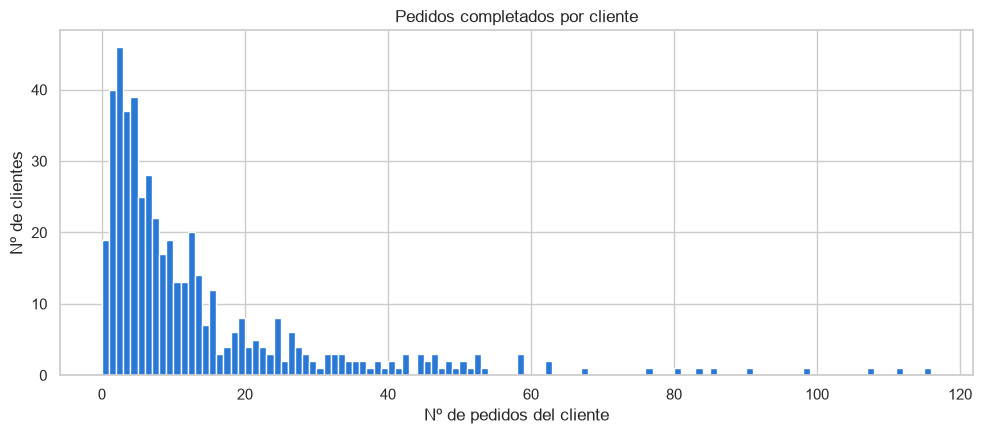

Mediana de pedidos por cliente: 7.0
Clientes con 1-3 pedidos: 123 | con 30 o más: 60 | sin pedidos completados: 19


In [18]:
fig, ax = plt.subplots()
ax.hist(clientes["pedidos"], bins=range(0, clientes["pedidos"].max() + 2), color=AZUL, edgecolor="white")
ax.set_title("Pedidos completados por cliente")
ax.set_xlabel("Nº de pedidos del cliente")
ax.set_ylabel("Nº de clientes")
fig.tight_layout()
plt.show()

print("Mediana de pedidos por cliente:", clientes["pedidos"].median())
print("Clientes con 1-3 pedidos:", int(clientes["pedidos"].between(1, 3).sum()),
      "| con 30 o más:", int((clientes["pedidos"] >= 30).sum()),
      "| sin pedidos completados:", int((clientes["pedidos"] == 0).sum()))

**Conclusión:** la mediana es de 7 pedidos completados por cliente, pero la distribución es muy desigual: 123 clientes tienen de 1 a 3 pedidos, 60 tienen 30 o más (el máximo es 115) y 19 no tienen ningún pedido completado.

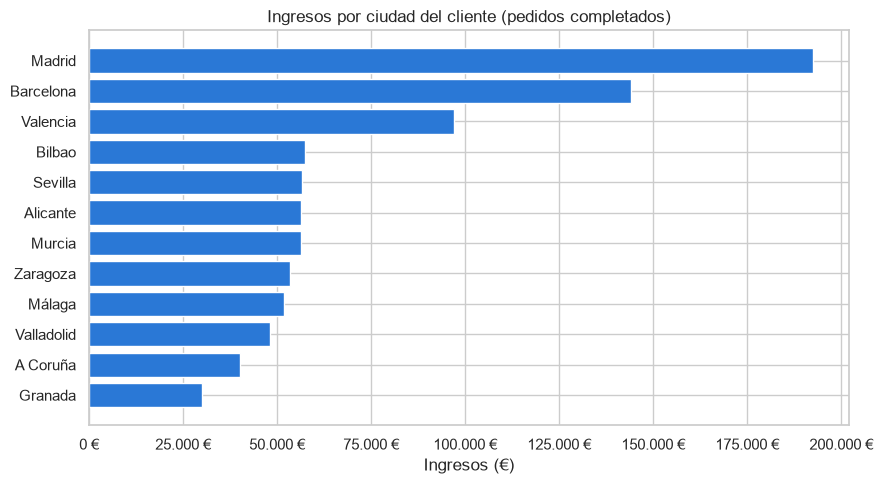

,ciudad,clientes,ingresos,cuota
0,Madrid,120,192420.89,"21,8 %"
1,Barcelona,76,144177.29,"16,3 %"
2,Valencia,45,96938.97,"11,0 %"
3,Bilbao,24,57473.85,"6,5 %"
4,Sevilla,41,56702.94,"6,4 %"
5,Alicante,29,56350.46,"6,4 %"
6,Murcia,27,56200.48,"6,4 %"
7,Zaragoza,27,53515.97,"6,1 %"
8,Málaga,32,51671.60,"5,8 %"
9,Valladolid,21,48004.90,"5,4 %"


In [19]:
# Ingresos por ciudad del cliente
ciudades = leer_sql("""
    SELECT
        c.ciudad,
        COUNT(DISTINCT c.id_cliente)         AS clientes,
        SUM(d.cantidad * d.precio_unitario)  AS ingresos
    FROM clientes AS c
        JOIN pedidos        AS p ON p.id_cliente = c.id_cliente
        JOIN detalle_pedido AS d ON d.id_pedido  = p.id_pedido
    WHERE p.estado = 'completado'
    GROUP BY c.ciudad
    ORDER BY ingresos DESC
""")
ciudades["cuota"] = ciudades["ingresos"] / ciudades["ingresos"].sum()

orden = ciudades.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(orden["ciudad"], orden["ingresos"], color=AZUL)
ax.set_title("Ingresos por ciudad del cliente (pedidos completados)")
ax.set_xlabel("Ingresos (€)")
ax.xaxis.set_major_formatter(FORMATO_EUROS)
fig.tight_layout()
plt.show()
ciudades.assign(cuota=ciudades["cuota"].map(porcentaje))

**Conclusión:** Madrid aporta 192.421 € (21,8 %), seguida de Barcelona (16,3 %) y Valencia (11,0 %); Granada es la última (29.880 €, 3,4 %). El orden sigue sobre todo al número de clientes de cada ciudad (Madrid tiene 120), no a que en una ciudad se gaste más por cliente.

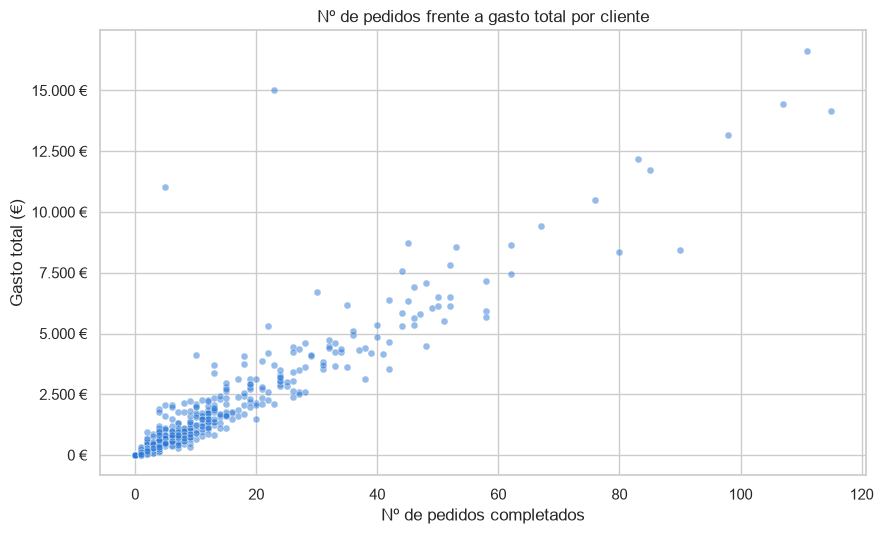

Correlación pedidos-gasto: 0.92
El 10 % de clientes que más gasta aporta el 41,9 % de los ingresos; su mínimo de pedidos es 5
Gasto mediano por pedido de un cliente: 123,48 €


,id_cliente,ciudad,pedidos,gasto,gasto_por_pedido
196,199,Murcia,5,11026.56,2205.31
428,435,Barcelona,23,15014.96,652.82
233,236,Murcia,2,952.49,476.24


In [20]:
# Dispersión: cada punto es un cliente
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(clientes["pedidos"], clientes["gasto"], color=AZUL, alpha=0.5, s=25, edgecolor="white", linewidth=0.5)
ax.set_title("Nº de pedidos frente a gasto total por cliente")
ax.set_xlabel("Nº de pedidos completados")
ax.set_ylabel("Gasto total (€)")
ax.yaxis.set_major_formatter(FORMATO_EUROS)
fig.tight_layout()
guardar(fig, "clientes_dispersion")
plt.show()

print("Correlación pedidos-gasto:", f'{clientes["pedidos"].corr(clientes["gasto"]):.2f}')
# Peso de los clientes que más compran
top10pct = clientes.nlargest(int(len(clientes) * 0.10), "gasto")
print("El 10 % de clientes que más gasta aporta el", porcentaje(top10pct["gasto"].sum() / clientes["gasto"].sum()),
      "de los ingresos; su mínimo de pedidos es", top10pct["pedidos"].min())

# Clientes que se salen de la nube: gastan mucho para los pedidos que hacen
clientes["gasto_por_pedido"] = clientes["gasto"] / clientes["pedidos"].where(clientes["pedidos"] > 0)
print("Gasto mediano por pedido de un cliente:", euros(clientes["gasto_por_pedido"].median(), 2))
clientes.nlargest(3, "gasto_por_pedido").round(2)

**Conclusión:** el número de pedidos y el gasto están muy relacionados (correlación 0,92), y el 10 % de los clientes que más gasta aporta el 41,9 % de los ingresos. Se intuyen grupos: una nube densa de clientes con pocos pedidos y poco gasto, y una cola de clientes que repiten mucho (de 30 a 115 pedidos). Además, dos puntos se salen de la nube: el cliente 199 gasta 2.205,31 € por pedido, cuando la mediana es 123,48 €. Los grupos los buscaremos con K-Means (S7) y a esos clientes raros, con Isolation Forest (S8).

## 6. Estados y métodos de pago

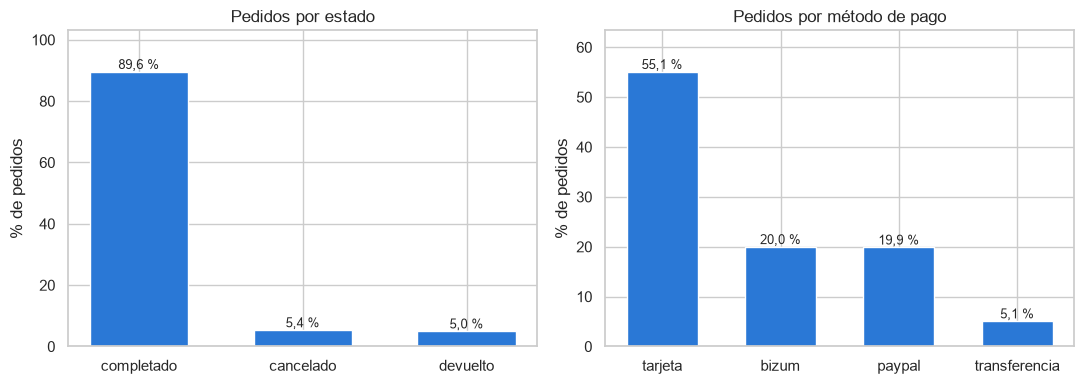

,estado,pedidos,porcentaje
0,completado,6541,89.6
1,cancelado,391,5.4
2,devuelto,365,5.0


,metodo_pago,pedidos,porcentaje
0,tarjeta,4017,55.1
1,bizum,1460,20.0
2,paypal,1450,19.9
3,transferencia,370,5.1


In [21]:
# Todos los pedidos (aquí sí entran cancelados y devueltos: es lo que queremos medir)
estados = leer_sql("""
    SELECT
        estado,
        COUNT(*)                                                    AS pedidos,
        ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM pedidos), 1) AS porcentaje
    FROM pedidos
    GROUP BY estado
    ORDER BY pedidos DESC
""")
metodos = leer_sql("""
    SELECT
        metodo_pago,
        COUNT(*)                                                    AS pedidos,
        ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM pedidos), 1) AS porcentaje
    FROM pedidos
    GROUP BY metodo_pago
    ORDER BY pedidos DESC
""")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, datos, columna, titulo in [(ax1, estados, "estado", "Pedidos por estado"),
                                   (ax2, metodos, "metodo_pago", "Pedidos por método de pago")]:
    ax.bar(datos[columna], datos["porcentaje"], color=AZUL, width=0.6)
    for x, valor in enumerate(datos["porcentaje"]):
        ax.text(x, valor, f"{valor:.1f} %".replace(".", ","), ha="center", va="bottom", fontsize=9)
    ax.set_title(titulo)
    ax.set_ylabel("% de pedidos")
    ax.set_xlabel("")
    ax.set_ylim(0, datos["porcentaje"].max() * 1.15)
fig.tight_layout()
plt.show()
display(estados)
display(metodos)

**Conclusión:** el 89,6 % de los pedidos se completa; el 5,4 % se cancela y el 5,0 % se devuelve, así que un 10,4 % de los pedidos no deja ingresos. En el pago domina la tarjeta (55,1 %), seguida de Bizum (20,0 %) y PayPal (19,9 %); la transferencia es casi residual (5,1 %).

## 7. Publicidad frente a ventas

Preparación de la regresión de la S6: ¿se vende más los meses en los que se invierte más?
Aquí solo se mira la relación; **no se entrena ningún modelo**.

In [22]:
# Tabla mensual con dos CTE (WITH): una agrega las campañas y otra las ventas.
# CASE WHEN convierte las filas de cada canal en columnas (un "pivot" en SQL).
publicidad = leer_sql("""
    WITH inversion_mes AS (
        SELECT
            mes,
            SUM(inversion)                                             AS inversion_total,
            SUM(CASE WHEN canal = 'google_ads' THEN inversion ELSE 0 END) AS google_ads,
            SUM(CASE WHEN canal = 'meta_ads'   THEN inversion ELSE 0 END) AS meta_ads,
            SUM(CASE WHEN canal = 'email'      THEN inversion ELSE 0 END) AS email
        FROM campanas
        GROUP BY mes
    ),
    ventas_mes AS (
        SELECT
            strftime('%Y-%m', p.fecha_pedido)    AS mes,
            COUNT(DISTINCT p.id_pedido)          AS pedidos,
            SUM(d.cantidad * d.precio_unitario)  AS ingresos
        FROM pedidos AS p
            JOIN detalle_pedido AS d ON d.id_pedido = p.id_pedido
        WHERE p.estado = 'completado'
        GROUP BY mes
    )
    SELECT i.*, v.pedidos, v.ingresos
    FROM inversion_mes AS i
        LEFT JOIN ventas_mes AS v ON v.mes = i.mes
    ORDER BY i.mes
""")
publicidad.round(2)

,mes,inversion_total,google_ads,meta_ads,email,pedidos,ingresos
0,2024-11,4805.81,3423.51,923.33,458.97,411,62425.84
1,2024-12,5149.78,2582.35,2184.11,383.32,372,50417.97
2,2025-01,4490.81,2228.52,2029.82,232.47,304,42475.15
3,2025-02,2909.23,1765.05,1026.49,117.69,201,27021.07
4,2025-03,2857.55,2146.12,538.11,173.32,232,27495.94
5,2025-04,2125.18,981.80,859.14,284.24,212,28589.63
6,2025-05,3651.81,2182.65,1342.11,127.05,318,39239.53
7,2025-06,3192.12,1709.02,1174.97,308.13,261,31654.56
8,2025-07,3506.27,1912.00,1367.38,226.89,257,33859.34
9,2025-08,4492.53,2533.86,1742.95,215.72,284,38823.50


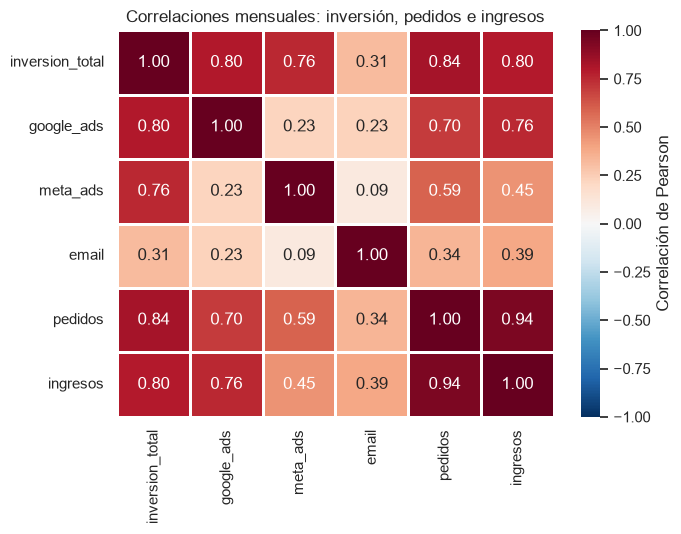

,inversion_total,google_ads,meta_ads,email,pedidos,ingresos
inversion_total,1.00,0.80,0.76,0.31,0.84,0.80
google_ads,0.80,1.00,0.23,0.23,0.70,0.76
meta_ads,0.76,0.23,1.00,0.09,0.59,0.45
email,0.31,0.23,0.09,1.00,0.34,0.39
pedidos,0.84,0.70,0.59,0.34,1.00,0.94
ingresos,0.80,0.76,0.45,0.39,0.94,1.00


In [23]:
# Mapa de calor de correlaciones (Pearson). Paleta divergente: rojo positivo, azul negativo, blanco = 0
correlaciones = publicidad.drop(columns="mes").corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", ax=ax, cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Correlaciones mensuales: inversión, pedidos e ingresos")
fig.tight_layout()
plt.show()
correlaciones.round(2)

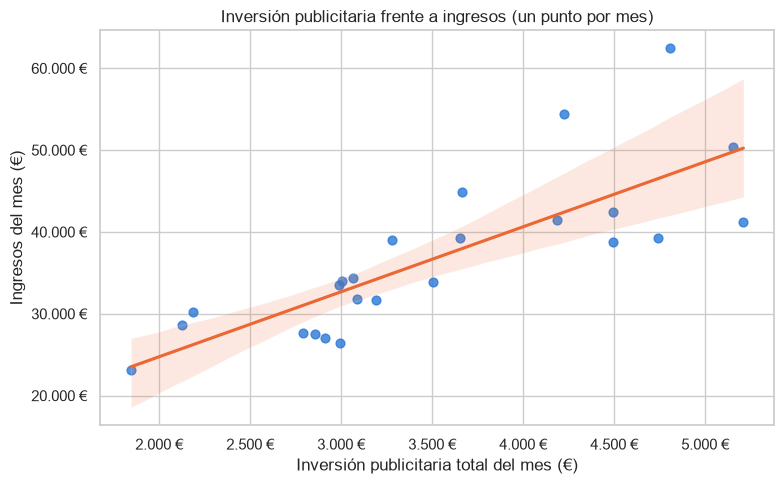

Correlación inversión-ingresos (24 meses): 0.80
Correlación inversión-pedidos  (24 meses): 0.84
Correlación inversión-ingresos sin nov-dic (20 meses): 0.80


In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
# seed=42: la banda de confianza de regplot se calcula con un bootstrap aleatorio;
# con semilla fija la imagen sale igual en cada ejecución
sns.regplot(data=publicidad, x="inversion_total", y="ingresos", ax=ax, seed=42,
            color=AZUL, scatter_kws={"s": 40}, line_kws={"color": NARANJA})
ax.set_title("Inversión publicitaria frente a ingresos (un punto por mes)")
ax.set_xlabel("Inversión publicitaria total del mes (€)")
ax.set_ylabel("Ingresos del mes (€)")
ax.xaxis.set_major_formatter(FORMATO_EUROS)
ax.yaxis.set_major_formatter(FORMATO_EUROS)
fig.tight_layout()
guardar(fig, "regresion")
plt.show()

# ¿Cuánto de la relación viene de la estacionalidad? Se repite sin noviembre ni diciembre
sin_nov_dic = publicidad[~pd.to_datetime(publicidad["mes"]).dt.month.isin([11, 12])]
print("Correlación inversión-ingresos (24 meses):", f'{publicidad["inversion_total"].corr(publicidad["ingresos"]):.2f}')
print("Correlación inversión-pedidos  (24 meses):", f'{publicidad["inversion_total"].corr(publicidad["pedidos"]):.2f}')
print(f"Correlación inversión-ingresos sin nov-dic ({len(sin_nov_dic)} meses):",
      f'{sin_nov_dic["inversion_total"].corr(sin_nov_dic["ingresos"]):.2f}')

**Conclusión:** los meses con más inversión venden más. La correlación entre inversión e ingresos es 0,80 (con los pedidos, 0,84), y sigue siendo 0,80 si quitamos noviembre y diciembre, así que no se explica solo por la temporada. Por canal, Google Ads es el que más se relaciona con los ingresos (0,76), por delante de Meta Ads (0,45) y email (0,39). Correlación no es causa, pero justifica probar una regresión lineal en la S6.

## 8. Conclusiones

1. **Ventas:** en 24 meses se ingresan 883.361 € con 6.541 pedidos completados (ticket mediano de 82,78 €).
2. **Estacionalidad:** noviembre y diciembre venden un 43,2 % más que la media del resto de meses.
3. **Publicidad:** la inversión mensual y los ingresos tienen una correlación de 0,80 (0,84 con el nº de pedidos), y se mantiene en 0,80 sin noviembre ni diciembre.
4. **Producto:** Electrónica aporta el 36,0 % de los ingresos y los tres productos más vendidos son de Electrónica y Premium. No hay un Pareto fuerte: el 80 % de los ingresos lo generan 33 de 60 productos (55,0 %).
5. **Clientes:** el 10 % que más gasta genera el 41,9 % de los ingresos; hay 60 clientes con 30 o más pedidos frente a 123 con solo de 1 a 3.
6. **Pedidos raros:** hay 25 pedidos de 8 a 12 líneas (cuando lo normal es de 1 a 4) y pedidos de hasta 11.730,42 €. Uno solo de 10.389,60 € explica el pico de 2026-06 (sin él, ese mes se queda en 43.962 €).
7. **Estados:** el 10,4 % de los pedidos se cancela (5,4 %) o se devuelve (5,0 %).

**Preguntas para las próximas semanas**

- **S6 · Regresión:** ¿cuántos euros de ingresos trae cada euro invertido en publicidad, y cuánto se debe a la estacionalidad?
- **S7 · K-Means:** ¿los grupos que se intuyen en la dispersión (clientes de pocas compras frente a clientes que repiten mucho) son segmentos reales con RFM?
- **S8 · Isolation Forest:** ¿detecta automáticamente los pedidos raros que hemos visto (muchas líneas, cantidades enormes, precios extraños) sin que se lo digamos?